In [2]:
from google.colab import files

uploaded = files.upload()

Saving Lab Session Data-2.xlsx to Lab Session Data-2.xlsx


In [3]:
import os

print(os.listdir())

['.config', 'Lab Session Data-2.xlsx', 'sample_data']


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.spatial.distance import minkowski

In [5]:
file = "Lab Session Data-2.xlsx"

xls = pd.ExcelFile(file)

print(xls.sheet_names)

['Purchase data', 'IRCTC Stock Price', 'thyroid0387_UCI', 'marketing_campaign']


In [10]:
def identify_feature_type(column):

    if pd.api.types.is_object_dtype(column):
        return "Nominal"

    elif pd.api.types.is_integer_dtype(column):

        if column.nunique() <= 10:
            return "Ordinal"

        else:
            return "Ratio"

    elif pd.api.types.is_float_dtype(column):
        return "Interval"

    else:
        return "Unknown"

In [8]:
def datatype_table(data):

    table = []

    for col in data.columns:

        dtype = identify_feature_type(data[col])

        table.append([col, dtype])

    return pd.DataFrame(table,
                        columns=["Feature",
                                 "Datatype"])

In [9]:
feature_types = datatype_table(df)

feature_types

,Feature,Datatype
0,ID,Ratio
1,Year_Birth,Ratio
2,Education,Nominal
3,Marital_Status,Nominal
4,Income,Interval
5,Kidhome,Ordinal
6,Teenhome,Ordinal
7,Dt_Customer,Nominal
8,Recency,Ratio
9,MntWines,Ratio


A2 Label Encoding

In [11]:
def label_encode(column):

    unique_values = sorted(column.dropna().unique())

    mapping = {}

    for i, value in enumerate(unique_values):

        mapping[value] = i

    encoded = column.map(mapping)

    return encoded, mapping

A3 One-Hot Encoding

In [15]:
def label_encode(column):

    column = column.astype(str)

    unique_values = column.unique()

    mapping = {}

    for index, value in enumerate(unique_values):
        mapping[value] = index

    encoded_column = column.map(mapping)

    return encoded_column, mapping

In [16]:
def one_hot_encode(column):

    column = column.astype(str)

    unique_values = column.unique()

    encoded = pd.DataFrame()

    for value in unique_values:

        encoded[column.name + "_" + str(value)] = (column == value).astype(int)

    return encoded

In [17]:
label_dataset = df.copy()

categorical_columns = ["Education", "Marital_Status"]

for column in categorical_columns:

    encoded_column, mapping = label_encode(label_dataset[column])

    label_dataset[column] = encoded_column

    print("\nColumn :", column)
    print("Mapping :", mapping)

print("\nDataset after Label Encoding")
print(label_dataset.head())

print("\nShape :", label_dataset.shape)


Column : Education
Mapping : {'Graduation': 0, 'PhD': 1, 'Master': 2, 'Basic': 3, '2n Cycle': 4}

Column : Marital_Status
Mapping : {'Single': 0, 'Together': 1, 'Married': 2, 'Divorced': 3, 'Widow': 4, 'Alone': 5, 'Absurd': 6, 'YOLO': 7}

Dataset after Label Encoding
     ID  Year_Birth  Education  Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957          0               0  58138.0        0         0   
1  2174        1954          0               0  46344.0        1         1   
2  4141        1965          0               1  71613.0        0         0   
3  6182        1984          0               1  26646.0        1         0   
4  5324        1981          1               2  58293.0        1         0   

           Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  \
0  2012-04-09 00:00:00       58       635  ...                  7   
1  2014-08-03 00:00:00       38        11  ...                  5   
2           21-08-2013       26       426  ...         

In [18]:
one_hot_dataset = df.copy()

categorical_columns = ["Education", "Marital_Status"]

for column in categorical_columns:

    encoded = one_hot_encode(one_hot_dataset[column])

    one_hot_dataset = one_hot_dataset.drop(columns=[column])

    one_hot_dataset = pd.concat([one_hot_dataset, encoded], axis=1)

In [19]:
print("Original Dataset Shape")
print(df.shape)

print()

print("Dataset Shape after One-Hot Encoding")
print(one_hot_dataset.shape)

print()

print("Number of Features Before Encoding :", len(df.columns))

print("Number of Features After Encoding :", len(one_hot_dataset.columns))

Original Dataset Shape
(2240, 29)

Dataset Shape after One-Hot Encoding
(2240, 40)

Number of Features Before Encoding : 29
Number of Features After Encoding : 40


In [20]:
one_hot_dataset.head()

,ID,Year_Birth,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,...,Education_Basic,Education_2n Cycle,Marital_Status_Single,Marital_Status_Together,Marital_Status_Married,Marital_Status_Divorced,Marital_Status_Widow,Marital_Status_Alone,Marital_Status_Absurd,Marital_Status_YOLO
0,5524,1957,58138.0,0,0,2012-04-09 00:00:00,58,635,88,546,...,0,0,1,0,0,0,0,0,0,0
1,2174,1954,46344.0,1,1,2014-08-03 00:00:00,38,11,1,6,...,0,0,1,0,0,0,0,0,0,0
2,4141,1965,71613.0,0,0,21-08-2013,26,426,49,127,...,0,0,0,1,0,0,0,0,0,0
3,6182,1984,26646.0,1,0,2014-10-02 00:00:00,26,11,4,20,...,0,0,0,1,0,0,0,0,0,0
4,5324,1981,58293.0,1,0,19-01-2014,94,173,43,118,...,0,0,0,0,1,0,0,0,0,0


A4. Develop Your Own Function for Generalized Minkowski Distance

In [21]:
def minkowski_distance(vector1, vector2, p):

    distance = 0

    for i in range(len(vector1)):

        distance += abs(vector1[i] - vector2[i]) ** p

    return distance ** (1 / p)

In [22]:
numeric_data = label_dataset.select_dtypes(include=["number"])

vector1 = numeric_data.iloc[0].values
vector2 = numeric_data.iloc[1].values

print("Vector 1")
print(vector1)

print("\nVector 2")
print(vector2)

Vector 1
[5.5240e+03 1.9570e+03 0.0000e+00 0.0000e+00 5.8138e+04 0.0000e+00
 0.0000e+00 5.8000e+01 6.3500e+02 8.8000e+01 5.4600e+02 1.7200e+02
 8.8000e+01 8.8000e+01 3.0000e+00 8.0000e+00 1.0000e+01 4.0000e+00
 7.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 3.0000e+00 1.1000e+01 1.0000e+00]

Vector 2
[2.1740e+03 1.9540e+03 0.0000e+00 0.0000e+00 4.6344e+04 1.0000e+00
 1.0000e+00 3.8000e+01 1.1000e+01 1.0000e+00 6.0000e+00 2.0000e+00
 1.0000e+00 6.0000e+00 2.0000e+00 1.0000e+00 1.0000e+00 2.0000e+00
 5.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00 0.0000e+00
 0.0000e+00 3.0000e+00 1.1000e+01 0.0000e+00]


In [23]:
manhattan_distance = minkowski_distance(vector1, vector2, 1)

euclidean_distance = minkowski_distance(vector1, vector2, 2)

print("Manhattan Distance =", manhattan_distance)

print("Euclidean Distance =", euclidean_distance)

Manhattan Distance = 16781.0
Euclidean Distance = 12290.371231171172


In [24]:
p_values = []

distance_values = []

for p in range(1, 11):

    distance = minkowski_distance(vector1, vector2, p)

    p_values.append(p)

    distance_values.append(distance)

    print("p =", p, "Distance =", distance)

p = 1 Distance = 16781.0
p = 2 Distance = 12290.371231171172
p = 3 Distance = 11884.37455405266
p = 4 Distance = 11813.182056643884
p = 5 Distance = 11798.3594656484
p = 6 Distance = 11795.03214977206
p = 7 Distance = 11794.251319225397
p = 8 Distance = 11794.062464516399
p = 9 Distance = 11794.015771376238
p = 10 Distance = 11794.004031784574


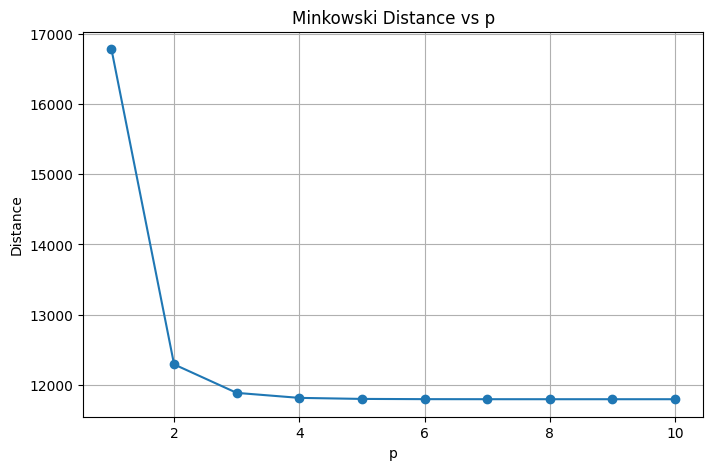

In [25]:
plt.figure(figsize=(8,5))

plt.plot(p_values, distance_values, marker="o")

plt.title("Minkowski Distance vs p")

plt.xlabel("p")

plt.ylabel("Distance")

plt.grid(True)

plt.show()

A6. Compare with SciPy Minkowski Distance

In [26]:
print("Comparison of Own Function and SciPy Function\n")

for p in range(1, 11):

    own_distance = minkowski_distance(vector1, vector2, p)

    scipy_distance = minkowski(vector1, vector2, p)

    print("p =", p)
    print("Own Function :", own_distance)
    print("SciPy        :", scipy_distance)
    print()

Comparison of Own Function and SciPy Function

p = 1
Own Function : 16781.0
SciPy        : 16781.0

p = 2
Own Function : 12290.371231171172
SciPy        : 12290.371231171172

p = 3
Own Function : 11884.37455405266
SciPy        : 11884.37455405266

p = 4
Own Function : 11813.182056643884
SciPy        : 11813.182056643884

p = 5
Own Function : 11798.3594656484
SciPy        : 11798.3594656484

p = 6
Own Function : 11795.03214977206
SciPy        : 11795.03214977206

p = 7
Own Function : 11794.251319225397
SciPy        : 11794.251319225397

p = 8
Own Function : 11794.062464516399
SciPy        : 11794.062464516399

p = 9
Own Function : 11794.015771376238
SciPy        : 11794.015771376238

p = 10
Own Function : 11794.004031784574
SciPy        : 11794.004031784574



A7. Write Your Own Functions for Dot Product and Euclidean Norm


In [27]:
def dot_product(vector1, vector2):

    result = 0

    for i in range(len(vector1)):
        result += vector1[i] * vector2[i]

    return result

In [28]:
def euclidean_norm(vector):

    total = 0

    for value in vector:
        total += value ** 2

    return total ** 0.5

In [29]:
own_dot = dot_product(vector1, vector2)

own_norm1 = euclidean_norm(vector1)

own_norm2 = euclidean_norm(vector2)

print("Own Dot Product =", own_dot)

print("Own Euclidean Norm of Vector 1 =", own_norm1)

print("Own Euclidean Norm of Vector 2 =", own_norm2)

Own Dot Product = 2710194336.0
Own Euclidean Norm of Vector 1 = 58439.10812974476
Own Euclidean Norm of Vector 2 = 46436.11243418208


In [30]:
numpy_dot = np.dot(vector1, vector2)

numpy_norm1 = np.linalg.norm(vector1)

numpy_norm2 = np.linalg.norm(vector2)

print("NumPy Dot Product =", numpy_dot)

print("NumPy Norm of Vector 1 =", numpy_norm1)

print("NumPy Norm of Vector 2 =", numpy_norm2)

NumPy Dot Product = 2710194336.0
NumPy Norm of Vector 1 = 58439.10812974476
NumPy Norm of Vector 2 = 46436.11243418208


In [31]:
print("Dot Product Comparison")

print("Own Function :", own_dot)

print("NumPy        :", numpy_dot)

print()

print("Norm Comparison for Vector 1")

print("Own Function :", own_norm1)

print("NumPy        :", numpy_norm1)

print()

print("Norm Comparison for Vector 2")

print("Own Function :", own_norm2)

print("NumPy        :", numpy_norm2)

Dot Product Comparison
Own Function : 2710194336.0
NumPy        : 2710194336.0

Norm Comparison for Vector 1
Own Function : 58439.10812974476
NumPy        : 58439.10812974476

Norm Comparison for Vector 2
Own Function : 46436.11243418208
NumPy        : 46436.11243418208


A8. Write Functions for Mean, Variance and Standard Deviation


In [32]:
def calculate_mean(data):

    total = 0

    for value in data:
        total += value

    return total / len(data)

In [33]:
def calculate_variance(data):

    mean = calculate_mean(data)

    total = 0

    for value in data:

        total += (value - mean) ** 2

    return total / len(data)

In [34]:
def calculate_standard_deviation(data):

    variance = calculate_variance(data)

    return variance ** 0.5

In [35]:
def dataset_statistics(dataset):

    numeric_dataset = dataset.select_dtypes(include=["number"])

    means = []

    variances = []

    standard_deviations = []

    columns = numeric_dataset.columns

    for column in columns:

        values = numeric_dataset[column].dropna().values

        means.append(calculate_mean(values))

        variances.append(calculate_variance(values))

        standard_deviations.append(calculate_standard_deviation(values))

    result = pd.DataFrame({

        "Feature": columns,
        "Mean": means,
        "Variance": variances,
        "Standard Deviation": standard_deviations

    })

    return result

In [36]:
own_statistics = dataset_statistics(label_dataset)

print("Statistics using Own Functions")

own_statistics

Statistics using Own Functions


,Feature,Mean,Variance,Standard Deviation
0,ID,5592.159821,1.053611e+07,3245.937415
1,Year_Birth,1968.805804,1.435538e+02,11.981394
2,Education,0.982143,1.580038e+00,1.256996
3,Marital_Status,1.496875,1.152669e+00,1.073624
4,Income,52247.251354,6.333978e+08,25167.396174
5,Kidhome,0.444196,2.897431e-01,0.538278
6,Teenhome,0.506250,2.963895e-01,0.544417
7,Recency,49.109375,8.384492e+02,28.955987
8,MntWines,303.935714,1.132472e+05,336.522251
9,MntFruits,26.302232,1.581220e+03,39.764555


A9. Compare with NumPy Functions



In [37]:
numeric_dataset = label_dataset.select_dtypes(include=["number"])

numpy_statistics = pd.DataFrame({

    "Feature": numeric_dataset.columns,

    "Mean": np.mean(numeric_dataset, axis=0),

    "Standard Deviation": np.std(numeric_dataset, axis=0)

})

print("Statistics using NumPy")

numpy_statistics

Statistics using NumPy


,Feature,Mean,Standard Deviation
ID,ID,5592.159821,3245.937415
Year_Birth,Year_Birth,1968.805804,11.981394
Education,Education,0.982143,1.256996
Marital_Status,Marital_Status,1.496875,1.073624
Income,Income,52247.251354,25167.396174
Kidhome,Kidhome,0.444196,0.538278
Teenhome,Teenhome,0.506250,0.544417
Recency,Recency,49.109375,28.955987
MntWines,MntWines,303.935714,336.522251
MntFruits,MntFruits,26.302232,39.764555


In [38]:
comparison = own_statistics.copy()

comparison["NumPy Mean"] = np.mean(numeric_dataset, axis=0).values

comparison["NumPy Std"] = np.std(numeric_dataset, axis=0).values

comparison

,Feature,Mean,Variance,Standard Deviation,NumPy Mean,NumPy Std
0,ID,5592.159821,1.053611e+07,3245.937415,5592.159821,3245.937415
1,Year_Birth,1968.805804,1.435538e+02,11.981394,1968.805804,11.981394
2,Education,0.982143,1.580038e+00,1.256996,0.982143,1.256996
3,Marital_Status,1.496875,1.152669e+00,1.073624,1.496875,1.073624
4,Income,52247.251354,6.333978e+08,25167.396174,52247.251354,25167.396174
5,Kidhome,0.444196,2.897431e-01,0.538278,0.444196,0.538278
6,Teenhome,0.506250,2.963895e-01,0.544417,0.506250,0.544417
7,Recency,49.109375,8.384492e+02,28.955987,49.109375,28.955987
8,MntWines,303.935714,1.132472e+05,336.522251,303.935714,336.522251
9,MntFruits,26.302232,1.581220e+03,39.764555,26.302232,39.764555


A10. Histogram of One Feature



In [39]:
feature = label_dataset["Income"].dropna()

mean_income = calculate_mean(feature.values)

variance_income = calculate_variance(feature.values)

print("Mean =", mean_income)

print("Variance =", variance_income)

Mean = 52247.25135379061
Variance = 633397830.1872728


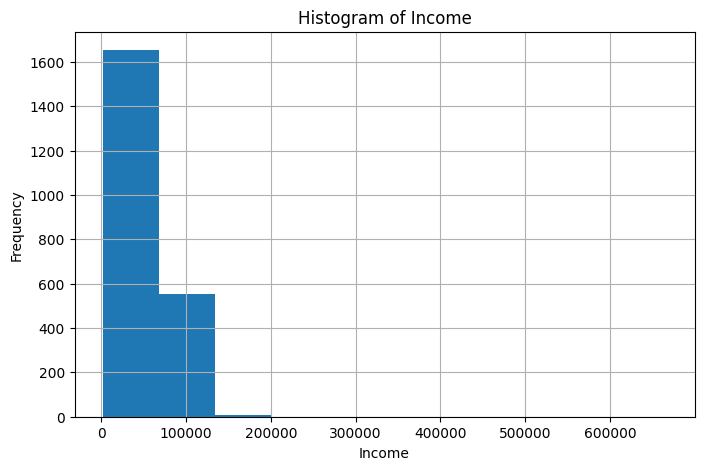

In [40]:
plt.figure(figsize=(8,5))

plt.hist(feature, bins=10)

plt.title("Histogram of Income")

plt.xlabel("Income")

plt.ylabel("Frequency")

plt.grid(True)

plt.show()

 A11. Own K-Means Algorithm



In [41]:
def euclidean_distance(point1, point2):

    total = 0

    for i in range(len(point1)):
        total += (point1[i] - point2[i]) ** 2

    return total ** 0.5

In [42]:
def assign_clusters(data, centroids):

    clusters = []

    for point in data:

        distances = []

        for centroid in centroids:
            distances.append(euclidean_distance(point, centroid))

        clusters.append(np.argmin(distances))

    return np.array(clusters)

In [43]:
def update_centroids(data, clusters, k):

    centroids = []

    for i in range(k):

        cluster_points = data[clusters == i]

        if len(cluster_points) == 0:
            centroids.append(data[np.random.randint(len(data))])

        else:
            centroids.append(np.mean(cluster_points, axis=0))

    return np.array(centroids)

In [44]:
def k_means(data, k, max_iterations=100):

    np.random.seed(42)

    random_index = np.random.choice(len(data), k, replace=False)

    centroids = data[random_index]

    for _ in range(max_iterations):

        clusters = assign_clusters(data, centroids)

        new_centroids = update_centroids(data, clusters, k)

        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return clusters, centroids

In [45]:
numeric_dataset = label_dataset.select_dtypes(include=["number"])

numeric_dataset = numeric_dataset.fillna(numeric_dataset.mean())

data = numeric_dataset.values

In [46]:
k = 3

clusters, centroids = k_means(data, k)

print("Cluster Labels")

print(clusters)

print()

print("Centroids")

print(centroids)

Cluster Labels
[0 0 1 ... 0 1 0]

Centroids
[[5.52747826e+03 1.96586722e+03 9.75323149e-01 1.55699177e+00
  5.42011540e+04 3.76028202e-01 8.02585194e-01 4.97379553e+01
  3.17895417e+02 2.08918919e+01 1.14428907e+02 2.85287897e+01
  2.02244418e+01 4.77414806e+01 3.04700353e+00 4.89071680e+00
  2.46180964e+00 6.41128085e+00 5.50528790e+00 6.22796710e-02
  9.40070505e-02 1.05757932e-02 2.46768508e-02 1.64512338e-02
  5.87544066e-03 3.00000000e+00 1.10000000e+01 1.08108108e-01]
 [5.66737891e+03 1.96773476e+03 8.30313015e-01 1.51400329e+00
  7.94481598e+04 7.57825371e-02 3.11367381e-01 4.89851730e+01
  6.32350906e+02 5.98682043e+01 4.21975288e+02 8.65074135e+01
  6.35469522e+01 7.20922570e+01 1.50906096e+00 5.36902801e+00
  5.66062603e+00 8.36902801e+00 3.02965404e+00 7.24876442e-02
  1.36738056e-01 2.53706755e-01 2.00988468e-01 2.63591433e-02
  4.94233937e-03 3.00000000e+00 1.10000000e+01 2.53706755e-01]
 [5.60416240e+03 1.97283504e+03 1.10741688e+00 1.41815857e+00
  2.90071969e+04 8.04347

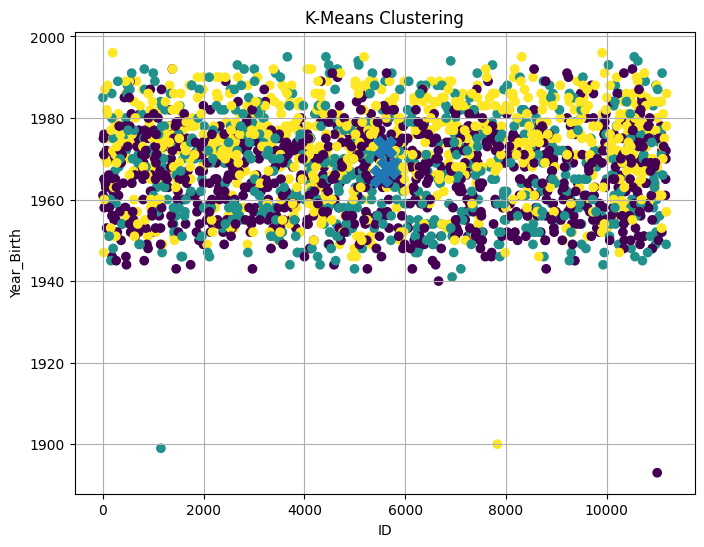

In [47]:
plt.figure(figsize=(8,6))

plt.scatter(data[:,0],
            data[:,1],
            c=clusters)

plt.scatter(centroids[:,0],
            centroids[:,1],
            marker="X",
            s=250)

plt.title("K-Means Clustering")

plt.xlabel(numeric_dataset.columns[0])

plt.ylabel(numeric_dataset.columns[1])

plt.grid(True)

plt.show()